# CDC PTB · перестановочная важность

## tl;dr

На фиксированной подвыборке validation 2023 проверяется, насколько ухудшается log loss после перестановки каждого исходного признака. Наибольший средний прирост в проверенном прогоне дал анамнез преждевременных родов: **+0,01016**. Маска пропуска переставляется вместе с полем. Для оценки разброса используются три повторения; это не кросс-валидационные фолды.

## Контекст и методы

Результат относится к выбранной модели и этой выборке из 50 000 записей. Важность не является коэффициентом причинного эффекта. Коррелирующие факторы способны делить вклад между собой.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .16})
BLUE, ORANGE, GOLD, SLATE = "#28628A", "#BA6234", "#B78918", "#3B4855"
from src.training.preterm_cdc import run_importance

## Результаты

In [4]:
importance = run_importance()
summary = importance.groupby("feature").agg(mean_delta=("delta_log_loss", "mean"), sd_delta=("delta_log_loss", "std"), mean_delta_brier=("delta_brier", "mean")).sort_values("mean_delta")
display(summary.round(5))

,mean_delta,sd_delta,mean_delta_brier
feature,,,
previous_terminations,0.00063,0.00022,0.00012
previous_cesarean,0.00071,0.00002,0.00021
prepregnancy_cigarettes_per_day,0.00079,0.00007,0.00025
chronic_hypertension,0.00183,0.00017,0.00063
preexisting_diabetes,0.00194,0.00015,0.00087
maternal_age_at_birth,0.00237,0.00024,0.00075
prepregnancy_bmi,0.00311,0.00023,0.00071
previous_live_births,0.00376,0.00038,0.00081
previous_preterm_birth,0.01016,0.00034,0.00385


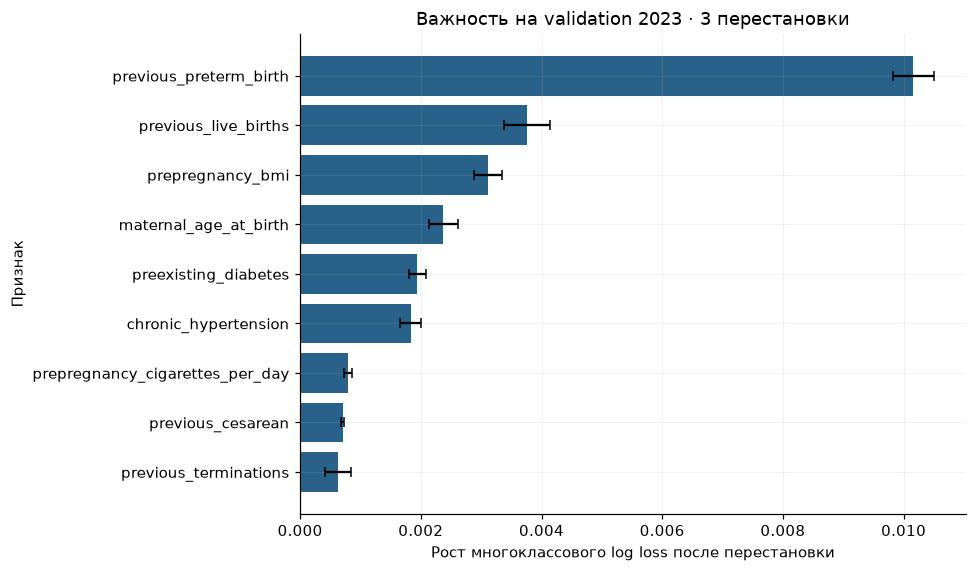

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.3))
ax.barh(summary.index, summary.mean_delta, xerr=summary.sd_delta, color=BLUE, error_kw={"capsize": 3})
ax.axvline(0, color=SLATE, linewidth=1)
ax.set(xlabel="Рост многоклассового log loss после перестановки", ylabel="Признак", title="Важность на validation 2023 · 3 перестановки")
plt.tight_layout(); plt.show()

## Выводы

Полоски ошибки показывают разброс **трёх перестановок одного validation-набора**, а не доверительные интервалы по пациенткам. Из-за отсутствия ID матери нельзя гарантировать независимость повторных беременностей.